# Chapter 8 · Itô's formula: interactive demos

Companion to Chapter 8 of the [IEOR 222 lecture notes](https://gennaroalberto.github.io/ieor222-financial-engineering/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/ieor222-financial-engineering/blob/main/code/notebooks/08-ito-formula.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/ieor222-financial-engineering#subdirectory=code"

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown

from ieor222.brownian import brownian_paths
from ieor222.itoformula import correlated_brownian, covariation, ito_check, left_sum, sgn
from ieor222.style import COBALT, GOLD, GREY, INK, use_style

use_style()

## 1. Itô's formula, one path at a time

Theorem 8.5 says that, almost surely, for every $t$,

$$f(t,W_t)=f(0,0)+\int_0^t\partial_t f(s,W_s)\,ds+\int_0^t\partial_x f(s,W_s)\,dW_s+\frac12\int_0^t\partial_{xx}f(s,W_s)\,ds .$$

Below, the integrals are computed by left-point sums on a grid of $n$ steps. The left panel compares $f(W_t)-f(0)$
with the full right side and with the chain rule of ordinary calculus, which drops the second-order term. The
right panel shows that the gap between them is $\frac12\int_0^t\partial_{xx}f\,ds$. For $e^{x-t/2}$ the
time derivative and the second-order term cancel, so Itô's formula has no $ds$-term at all, while the chain
rule (which keeps the time derivative) is off by $\frac12\int_0^t f\,ds$.

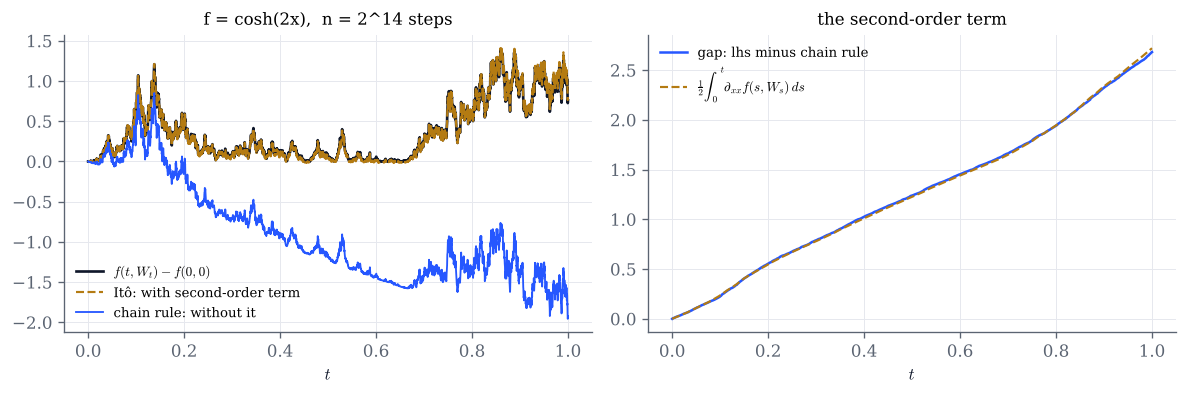

In [2]:
FUNCTIONS = {
    "x^2":        (lambda t, x: x**2,             lambda t, x: 2 * x,              lambda t, x: 2 + 0 * x,          None),
    "x^3":        (lambda t, x: x**3,             lambda t, x: 3 * x**2,           lambda t, x: 6 * x,              None),
    "cos(3x)":    (lambda t, x: np.cos(3 * x),    lambda t, x: -3 * np.sin(3 * x), lambda t, x: -9 * np.cos(3 * x), None),
    "cosh(2x)":   (lambda t, x: np.cosh(2 * x),   lambda t, x: 2 * np.sinh(2 * x), lambda t, x: 4 * np.cosh(2 * x), None),
    "exp(x-t/2)": (lambda t, x: np.exp(x - t / 2), lambda t, x: np.exp(x - t / 2), lambda t, x: np.exp(x - t / 2),
                   lambda t, x: -0.5 * np.exp(x - t / 2)),
}

def ito_path(f="cosh(2x)", log2_steps=14, seed=3):
    F, Fx, Fxx, Ft = FUNCTIONS[f]
    t, W = brownian_paths(T=1.0, n_steps=2**log2_steps, n_paths=1, seed=seed)
    r = ito_check(t, W, F, Fx, Fxx, f_t=Ft)
    step = max(1, len(t) // 4000)                 # plot at most about 4000 points
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
    ax.plot(t[::step], r["lhs"][0, ::step], color=INK, lw=1.6, label="$f(t,W_t)-f(0,0)$")
    ax.plot(t[::step], r["rhs"][0, ::step], color=GOLD, lw=1.3, ls="--", label="Itô: with second-order term")
    ax.plot(t[::step], r["first_order"][0, ::step], color=COBALT, lw=1.1, label="chain rule: without it")
    ax.set(xlabel="$t$", title=f"f = {f},  n = 2^{log2_steps} steps")
    ax.legend(fontsize=8)
    gap = r["lhs"] - r["first_order"]
    ax2.plot(t[::step], gap[0, ::step], color=COBALT, lw=1.5, label="gap: lhs minus chain rule")
    ax2.plot(t[::step], r["second_order"][0, ::step], color=GOLD, lw=1.3, ls="--",
             label="$\\frac{1}{2}\\int_0^t \\partial_{xx} f(s,W_s)\\,ds$")
    ax2.set(xlabel="$t$", title="the second-order term")
    ax2.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

ito_path()

In [3]:
# Explore: coarse grids (few steps) versus fine grids, and different functions.
interact(ito_path,
         f=Dropdown(options=list(FUNCTIONS), value="cosh(2x)", description="f"),
         log2_steps=IntSlider(value=14, min=4, max=18, continuous_update=False, description="log2 n"),
         seed=IntSlider(value=3, min=0, max=100, continuous_update=False, description="seed"));

## 2. Covariation and the product rule

Two Brownian motions $B^1, B^2$ with correlation $\rho$ are built as $B = LW$ from independent ones, with $LL^\top$
the correlation matrix. Their covariation $[B^1,B^2]_t=\sum_j \delta_j B^1\,\delta_j B^2$ (in the limit) is
$\rho t$, whatever the path: the rule $dB^1\,dB^2=\rho\,dt$ (Lemma 8.16 and the paragraph after
Theorem 8.17). The right panel checks the product rule of Corollary 8.18 on one path,

$$B^1_tB^2_t=\int_0^t B^1_s\,dB^2_s+\int_0^t B^2_s\,dB^1_s+[B^1,B^2]_t ,$$

where the covariation is exactly the term that ordinary integration by parts misses.

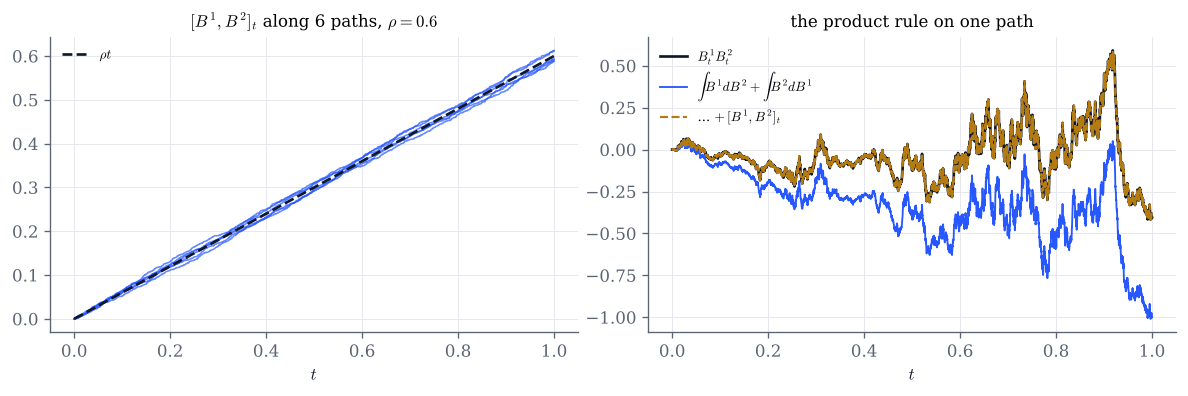

In [4]:
def product_rule(rho=0.6, log2_steps=12, seed=0):
    t, B = correlated_brownian(T=1.0, n_steps=2**log2_steps, corr=rho, n_paths=6, seed=seed)
    X, Y = B[:, 0], B[:, 1]
    cov = covariation(X, Y)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
    ax.plot(t, cov.T, color=COBALT, lw=0.9, alpha=0.7)
    ax.plot(t, rho * t, color=INK, lw=1.6, ls="--", label="$\\rho t$")
    ax.set(xlabel="$t$", title=f"$[B^1,B^2]_t$ along 6 paths, $\\rho={rho}$")
    ax.legend(fontsize=8)
    ito_parts = left_sum(X, Y) + left_sum(Y, X)
    ax2.plot(t, X[0] * Y[0], color=INK, lw=1.6, label="$B^1_tB^2_t$")
    ax2.plot(t, ito_parts[0], color=COBALT, lw=1.1, label="$\\int B^1 dB^2+\\int B^2 dB^1$")
    ax2.plot(t, ito_parts[0] + cov[0], color=GOLD, lw=1.3, ls="--", label="... $+\\,[B^1,B^2]_t$")
    ax2.set(xlabel="$t$", title="the product rule on one path")
    ax2.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

product_rule()

In [5]:
# Explore: try rho = 0, rho = -1 and rho = 1. When does ordinary integration by parts get it right?
interact(product_rule,
         rho=FloatSlider(value=0.6, min=-1.0, max=1.0, step=0.05, continuous_update=False, description="ρ"),
         log2_steps=IntSlider(value=12, min=4, max=16, continuous_update=False, description="log2 n"),
         seed=IntSlider(value=0, min=0, max=100, continuous_update=False, description="seed"));

## 3. Lévy's characterization

Theorem 8.20: a continuous martingale $M$ with $M_0=0$ and $[M,M]_t=t$ is a Brownian motion. For an Itô
integral $M_t=\int_0^t\Delta_s\,dW_s$ the condition reads $\Delta_s^2=1$. Choose an integrand below: the first
three have $|\Delta|=1$, and $M$ is a Brownian motion although it is not $W$; the last one does not, and $M$ is
not a standard Brownian motion. The left panel shows one path of $W$ and of $M$, with the quadratic variation
of $M$ along that path; the right panel shows the law of $M_1$ over many paths.

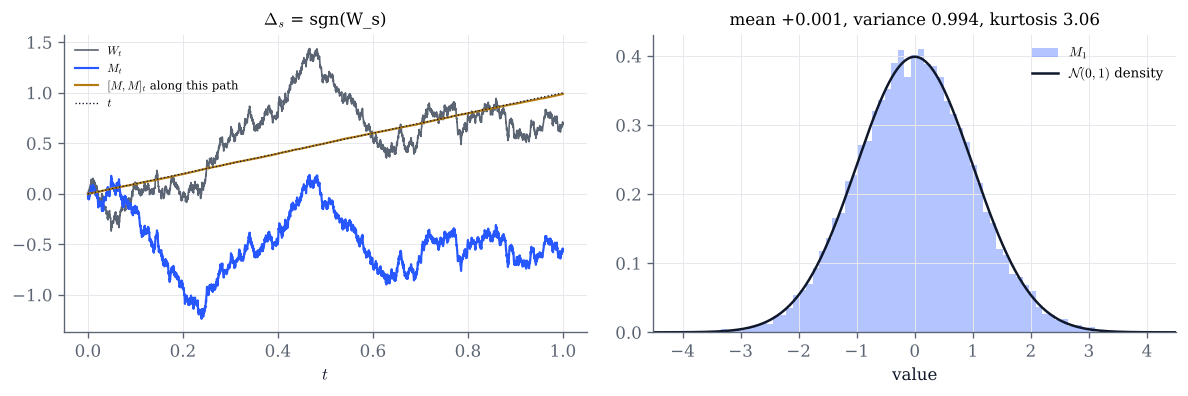

In [6]:
INTEGRANDS = {
    "sgn(W_s)":              lambda t, W, a: sgn(W),
    "sgn(W_s - a)":          lambda t, W, a: sgn(W - a),
    "sgn(sin(2π s / a))":    lambda t, W, a: sgn(np.sin(2 * np.pi * t / a)) + 0 * W,
    "1 + sgn(W_s)/2":        lambda t, W, a: 1 + 0.5 * sgn(W),
}

def levy(integrand="sgn(W_s)", a=0.3, n_paths=20_000, seed=1):
    # one path on a fine grid for the left panel, many paths on a coarser grid for the law of M_1
    tf, Wf = brownian_paths(T=1.0, n_steps=2**14, n_paths=1, seed=seed + 1000)
    Mf = left_sum(INTEGRANDS[integrand](tf, Wf, a), Wf)[0]
    t, W = brownian_paths(T=1.0, n_steps=500, n_paths=n_paths, seed=seed)
    M = left_sum(INTEGRANDS[integrand](t, W, a), W)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
    step = 4
    ax.plot(tf[::step], Wf[0, ::step], color=GREY, lw=1.0, label="$W_t$")
    ax.plot(tf[::step], Mf[::step], color=COBALT, lw=1.3, label="$M_t$")
    ax.plot(tf[::step], covariation(Mf, Mf)[::step], color=GOLD, lw=1.3, label="$[M,M]_t$ along this path")
    ax.plot(tf, tf, color=INK, lw=0.8, ls=":", label="$t$")
    ax.set(xlabel="$t$", title=f"$\\Delta_s$ = {integrand}")
    ax.legend(fontsize=7)
    m = M[:, -1]
    ax2.hist(m, bins=70, density=True, color=COBALT, alpha=0.35, label="$M_1$")
    x = np.linspace(-4.5, 4.5, 400)
    ax2.plot(x, np.exp(-x**2 / 2) / np.sqrt(2 * np.pi), color=INK, lw=1.5, label="$\\mathcal{N}(0,1)$ density")
    kurt = np.mean((m - m.mean())**4) / m.var()**2
    ax2.set(xlim=(-4.5, 4.5), xlabel="value",
            title=f"mean {m.mean():+.3f}, variance {m.var():.3f}, kurtosis {kurt:.2f}")
    ax2.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

levy()

In [7]:
# Explore: the level a is used by the second and third integrands.
interact(levy,
         integrand=Dropdown(options=list(INTEGRANDS), value="sgn(W_s)", description="Δ"),
         a=FloatSlider(value=0.3, min=0.05, max=1.0, step=0.05, continuous_update=False, description="a"),
         n_paths=IntSlider(value=20_000, min=2_000, max=60_000, step=2_000, continuous_update=False, description="paths"),
         seed=IntSlider(value=1, min=0, max=100, continuous_update=False, description="seed"));

## Things to try

- In section 1, choose $f(x)=x^2$. What is the gap on the right, exactly, and why is it the same on every path?
  For which of the functions can the gap decrease, and what property of $f$ decides it?
- In section 1, take very few steps ($n=2^4$) and then many. Which of the two curves on the left is sensitive to the grid?
- In section 2, set $\rho=0$: the covariation is not identically zero on a finite grid. How large are its fluctuations,
  and how do they change with $n$?
- In section 3, compute $[M,M]_t$ for $\Delta_s=1+\frac12\mathrm{sgn}(W_s)$ by hand. Which hypothesis of Lévy's theorem fails, and
  how does the variance of $M_1$ reflect it?